In [57]:
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits import mplot3d
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("/content/drive/MyDrive/EnergyPrice.csv") # csv file from Data.gov Link: https://catalog.data.gov/dataset/energy-prices-per-physical-unit-by-sector-beginning-1970?from_hint=eyJxIjoiZ2FzIHByaWNlIiwic29ydCI6InJlbGV2YW5jZSJ9

In [59]:
df

,Year,GDP Deflator,Sector,Coal ($/Ton),Distillate (cents/gallon),Residual ($/barrel),Kerosene (cents/gallon),Propane (cents/gallon),Natural Gas ($/Mcf),Electricity (cents/kWh),Wood ($/Cord),Motor Gasoline (cents/gallon),Jet Fuel (cents/gallon)
0,1970,0.132665,Commercial,$11.14,15.81,$2.64,9.86,12.78,$1.21,2.66,NaN,NaN,NaN
1,1970,0.132665,Industrial,$13.19,9.71,$3.08,9.86,13.50,$0.70,1.20,NaN,NaN,NaN
2,1970,0.132665,Residential,$33.18,19.83,NaN,21.06,23.84,$1.41,3.01,$8.00,NaN,NaN
3,1970,0.132665,Transportation,NaN,19.97,$2.33,NaN,12.78,$0.00,1.64,NaN,36.52,9.72
4,1971,0.138360,Commercial,$12.93,16.78,$3.33,10.67,12.48,$1.28,3.04,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
207,2021,0.925902,Transportation,NaN,338.78,$68.97,NaN,193.24,$12.43,12.67,NaN,287.01,198.45
208,2022,1.000000,Commercial,$0.00,415.30,$116.88,511.92,201.01,$10.37,18.19,NaN,NaN,NaN
209,2022,1.000000,Industrial,$89.53,378.07,$116.88,401.22,191.87,$11.37,7.55,NaN,NaN,NaN
210,2022,1.000000,Residential,$0.00,386.45,NaN,511.92,326.30,$16.43,22.08,$209.60,NaN,NaN


# Step 1: Linear Regression

Coefficients:  [[0.60186182]]
Intercept:  [29.80997119]
Mean squared error: 1309.62
Coefficient of determination: 0.77


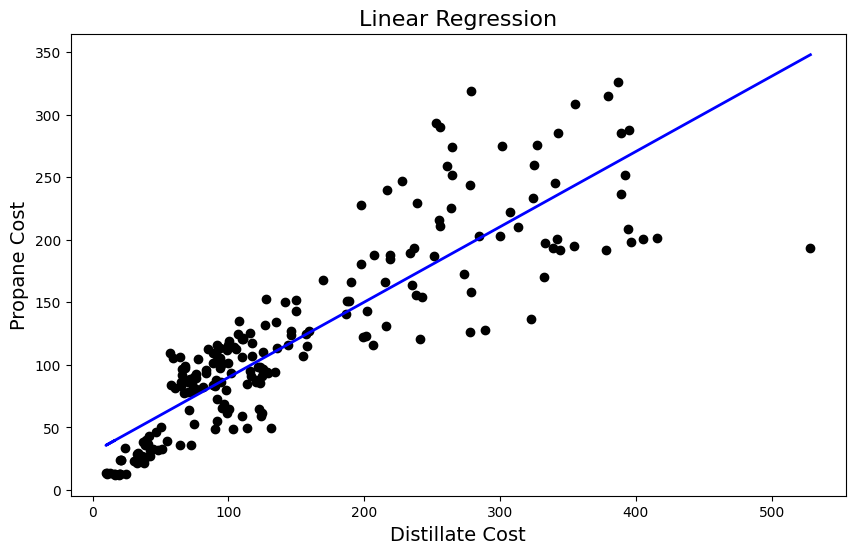

In [60]:
X = df[["Distillate (cents/gallon)"]].values.reshape(-1, 1)
y = df[["Propane (cents/gallon)"]].values.reshape(-1, 1)

train, test = train_test_split(df, train_size=0.70, random_state=0)

linearModel = LinearRegression()
linearModel.fit(X, y)

yPredicted = linearModel.predict(X)

print("Coefficients: ", linearModel.coef_)
print("Intercept: ", linearModel.intercept_)
print("Mean squared error: %.2f" % mean_squared_error(y, yPredicted))
print("Coefficient of determination: %.2f" % r2_score(y, yPredicted))

plt.figure(figsize=(10, 6))

plt.scatter(X, y, color="black")
plt.plot(X, yPredicted, color="blue", linewidth=2)
plt.xlabel("Distillate Cost", fontsize=14)
plt.ylabel("Propane Cost", fontsize=14)
plt.title("Linear Regression", fontsize=16)
plt.show()

# Step 2: Multiple Linear Regression

Coefficients:  [[0.40887673 5.79979739]]
Intercept:  [19.06185424]
Mean squared error: 1064.30
Coefficient of determination: 0.81


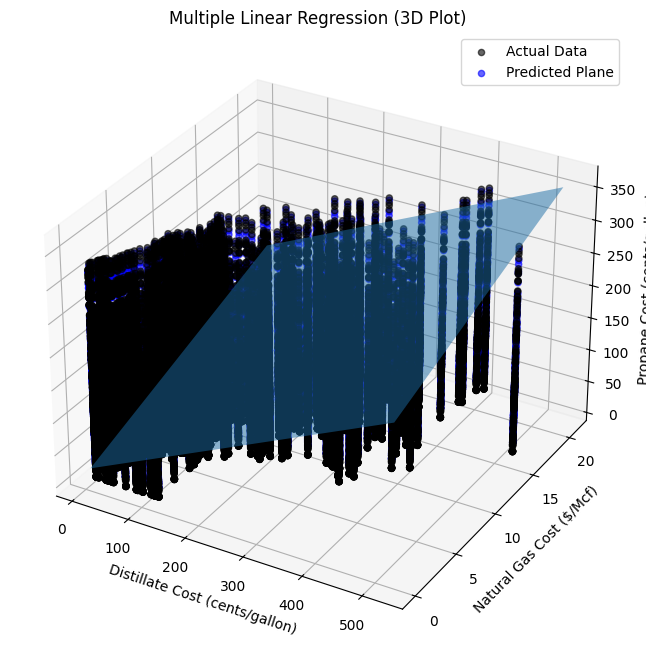

In [63]:
# Clean the Natural Gas column to remove dollar signs and convert to numeric values
if df["Natural Gas ($/Mcf)"].dtype == 'object':
    df["Natural Gas ($/Mcf)"] = df["Natural Gas ($/Mcf)"].str.replace('$', '', regex=False).astype(float)

X = df[["Distillate (cents/gallon)", "Natural Gas ($/Mcf)"]].values
y = df[["Propane (cents/gallon)"]].values

train, test = train_test_split(df, train_size=0.70, random_state=0)

linearModel = LinearRegression()
linearModel.fit(X, y)

yPredicted = linearModel.predict(X)

print("Coefficients: ", linearModel.coef_)
print("Intercept: ", linearModel.intercept_)
print("Mean squared error: %.2f" % mean_squared_error(y, yPredicted))
print("Coefficient of determination: %.2f" % r2_score(y, yPredicted))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the actual data points
ax.scatter(X[:, 0], X[:, 1], y, color='black', label='Actual Data', alpha=0.6)

# Plot the regression predictions
ax.scatter(X[:, 0], X[:, 1], yPredicted, color='blue', label='Predicted Plane', alpha=0.6)

xDeltaAccel, xDeltaWeight = np.meshgrid(
    np.linspace(X[:, 0].min(), X[:, 0].max(), 2),
    np.linspace(X[:, 1].min(), X[:, 1].max(), 2),
)
# Compute predicted MPG (z value) for grid values
yDeltaMPG = (
    linearModel.intercept_[0]
    + linearModel.coef_[0][0] * xDeltaAccel
    + linearModel.coef_[0][1] * xDeltaWeight
)
ax.plot_surface(xDeltaAccel, xDeltaWeight, yDeltaMPG, alpha=0.5)

ax.set_xlabel('Distillate Cost (cents/gallon)')
ax.set_ylabel('Natural Gas Cost ($/Mcf)')
ax.set_zlabel('Propane Cost (cents/gallon)')
ax.set_title('Multiple Linear Regression (3D Plot)')
plt.legend()
plt.show()

# Step 3: Logistic Regression

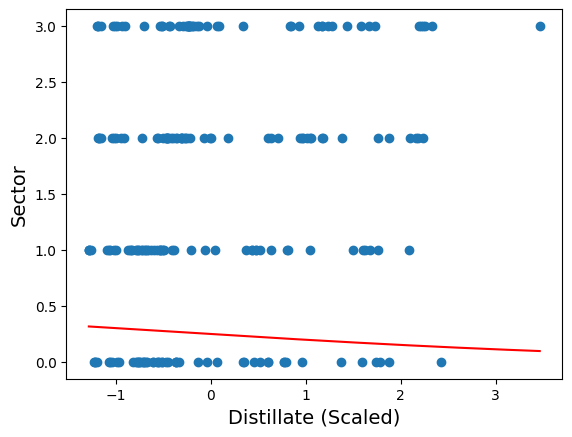

In [62]:
df.loc[df["Sector"] == "Commercial", "Sector"] = 0
df.loc[df["Sector"] == "Industrial", "Sector"] = 1
df.loc[df["Sector"] == "Residential", "Sector"] = 2
df.loc[df["Sector"] == "Transportation", "Sector"] = 3

X = df[["Distillate (cents/gallon)"]].values.reshape(-1, 1)
y = df[["Sector"]].values.reshape(-1, 1).astype(int)

# Instantiate the scaler and scale the feature matrix X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

train, test = train_test_split(df, train_size=0.70, random_state=0)

logisticModel = LogisticRegression()
logisticModel.fit(X_scaled, np.ravel(y.astype(int)))

yPredicted = logisticModel.predict(X_scaled)

# Plot the actual data against scaled features
plt.scatter(X_scaled, y)
xDelta = np.linspace(X_scaled.min(), X_scaled.max(), 10000)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("Distillate (Scaled)", fontsize=14)
plt.ylabel("Sector", fontsize=14)
plt.show()

# Conclusion

I mostly followed the zybooks examples.

For Linear Regression, the model seemed to fit well with the correlation between distillate and propane costs.

For Multiple Linear Regression, I tried to visualize the plane according to the predicted data. However I am not sure what wnt wrong.

For Logistic Regression, I probably should have only focused on two sectors instead of trying to fit all four.